In [3]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import PPO
from stable_baselines3.common.evaluation import evaluate_policy

In [4]:
class DomainRandomizedCartPole(gym.Wrapper):
    def __init__(self, env):
        super().__init__(env)

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        # Randomize physics parameters
        self.env.unwrapped.masscart = self.env.np_random.uniform(0.5, 5.0)
        self.env.unwrapped.masspole = self.env.np_random.uniform(0.05, 1.0)
        self.env.unwrapped.force_mag = self.env.np_random.uniform(10.0, 30.0)
        return obs, info

In [5]:
print("--- Training Baseline (300k steps) ---")
env_baseline = gym.make("CartPole-v1")
model_baseline = PPO("MlpPolicy", env_baseline, verbose=0)
model_baseline.learn(total_timesteps=300000)

--- Training Baseline (300k steps) ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [6]:
print("--- Training Domain-Randomized (300k steps) ---")
env_randomized = DomainRandomizedCartPole(gym.make("CartPole-v1"))
model_randomized = PPO("MlpPolicy", env_randomized, verbose=0)
model_randomized.learn(total_timesteps=300000)

--- Training Domain-Randomized (300k steps) ---


In [7]:
print("--- Evaluating on Unseen Test Environment ---")
test_env = gym.make("CartPole-v1")
test_env.unwrapped.masscart = 4.0
test_env.unwrapped.masspole = 0.5
test_env.unwrapped.force_mag = 15.0

--- Evaluating on Unseen Test Environment ---


In [8]:
mean_baseline, _ = evaluate_policy(model_baseline, test_env, n_eval_episodes=20)
mean_randomized, _ = evaluate_policy(model_randomized, test_env, n_eval_episodes=20)

/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


In [9]:
print(f"Baseline Reward: {mean_baseline}")
print(f"Randomized Reward: {mean_randomized}")

Baseline Reward: 500.0
Randomized Reward: 500.0


In [10]:
labels = ['Standard Baseline', 'Domain Randomized']
rewards = [mean_baseline, mean_randomized]

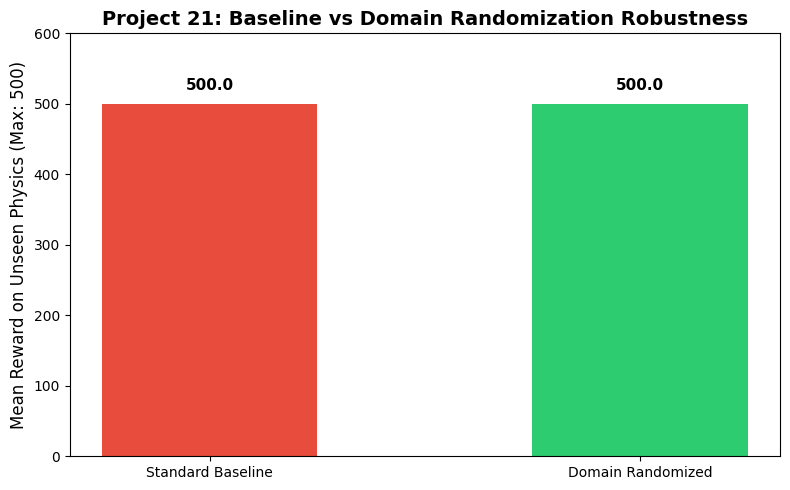

In [11]:
plt.figure(figsize=(8, 5))
bars = plt.bar(labels, rewards, color=['#e74c3c', '#2ecc71'], width=0.5)
plt.ylabel('Mean Reward on Unseen Physics (Max: 500)', fontsize=12)
plt.title('Project 21: Baseline vs Domain Randomization Robustness', fontsize=14, fontweight='bold')
plt.ylim(0, 600)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 15, f"{yval:.1f}", ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('domain_randomization_results.png', dpi=300)
plt.show()

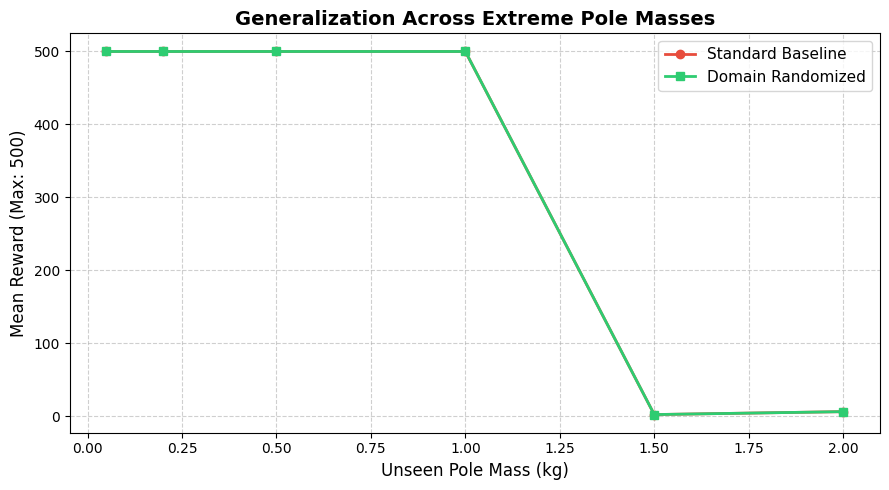

Saved 'generalization_curve.png' successfully!


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3.common.evaluation import evaluate_policy

# Test across a range of pole masses
pole_masses = [0.05, 0.2, 0.5, 1.0, 1.5, 2.0]
baseline_scores = []
randomized_scores = []

for pm in pole_masses:
    temp_env = gym.make("CartPole-v1")
    temp_env.unwrapped.masspole = pm

    mean_b, _ = evaluate_policy(model_baseline, temp_env, n_eval_episodes=10)
    mean_r, _ = evaluate_policy(model_randomized, temp_env, n_eval_episodes=10)

    baseline_scores.append(mean_b)
    randomized_scores.append(mean_r)

# Plotting the robustness curve
plt.figure(figsize=(9, 5))
plt.plot(pole_masses, baseline_scores, marker='o', color='#e74c3c', linewidth=2, label='Standard Baseline')
plt.plot(pole_masses, randomized_scores, marker='s', color='#2ecc71', linewidth=2, label='Domain Randomized')
plt.xlabel('Unseen Pole Mass (kg)', fontsize=12)
plt.ylabel('Mean Reward (Max: 500)', fontsize=12)
plt.title('Generalization Across Extreme Pole Masses', fontsize=14, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('generalization_curve.png', dpi=300)
plt.show()
print("Saved 'generalization_curve.png' successfully!")